# Critical zone: which depth changed?

**Question.** Following rainfall, you measure a frequency-dependent velocity decrease. Can the data distinguish the upper 10 m from the 10–50 m weathered layer? What if a temperature-related signal occurs at the same time?

This is a **synthetic, field-scale experiment**, not observations or a calibrated model of Shale Hills. We choose a 250 m/s surficial layer, 650 m/s weathered material, and a 1500 m/s substrate. All depths are metres, positive downward. The data are **direct fundamental Rayleigh phase changes**, with positive values meaning faster propagation; 0.001 is 0.1%.

Oakley et al. (2021) demonstrate why temperature and water observations matter in critical-zone monitoring. Their measurements use **coda MWCS**, which is a different observable from the phase changes modeled here. We use that study to motivate competing processes, not to transfer its coda depth sensitivity: [study](https://doi.org/10.1029/2020JF005823).


In [1]:
import sys
from pathlib import Path

# Run from the repository root or its tutorials/ directory.
root = Path.cwd().resolve()
if root.name == "tutorials":
    root = root.parent
if not (root / "src" / "gesc").is_dir():
    raise RuntimeError("Run this notebook from the gesc-python checkout.")
sys.path.insert(0, str(root))
sys.path.insert(0, str(root / "src"))
import matplotlib.pyplot as plt
import numpy as np

from gesc import solve_modes
from gesc.inversion import LinearInverseRequest, infer_time_lapse
from gesc.sensitivity import linearize_phase, perturb_model
from tutorials.plotting import emit_metrics, model_table, report_figure, sensitivity_figure, style
from tutorials.scenarios import correlated_covariance, phase_observation, select_band

style()
np.set_printoptions(precision=5, suppress=True)
%matplotlib inline

## 1. Make the reference structure explicit

Use 10–18 Hz here. This band samples overlapping shallow depths; it provides little leverage on the entire halfspace below 50 m. Wider bands in this high-contrast model need closer frequency sampling and careful mode identification.

These values are teaching assumptions. A site application needs a locally constrained background model and its uncertainty. Density is explicit; Vp and density stay fixed when we perturb Vs. The halfspace is its own unknown, rather than being silently held fixed.


Depth (m),Vp (m/s),Vs (m/s),Density (kg/m³)
0–10,800.0,250.0,1700.0
10–50,1800.0,650.0,2100.0
50–∞,3000.0,1500.0,2400.0


Frequencies (Hz): (10.3, 12.0, 14.0, 16.0, 18.0)
Locked numerical bottom (m): 800.0


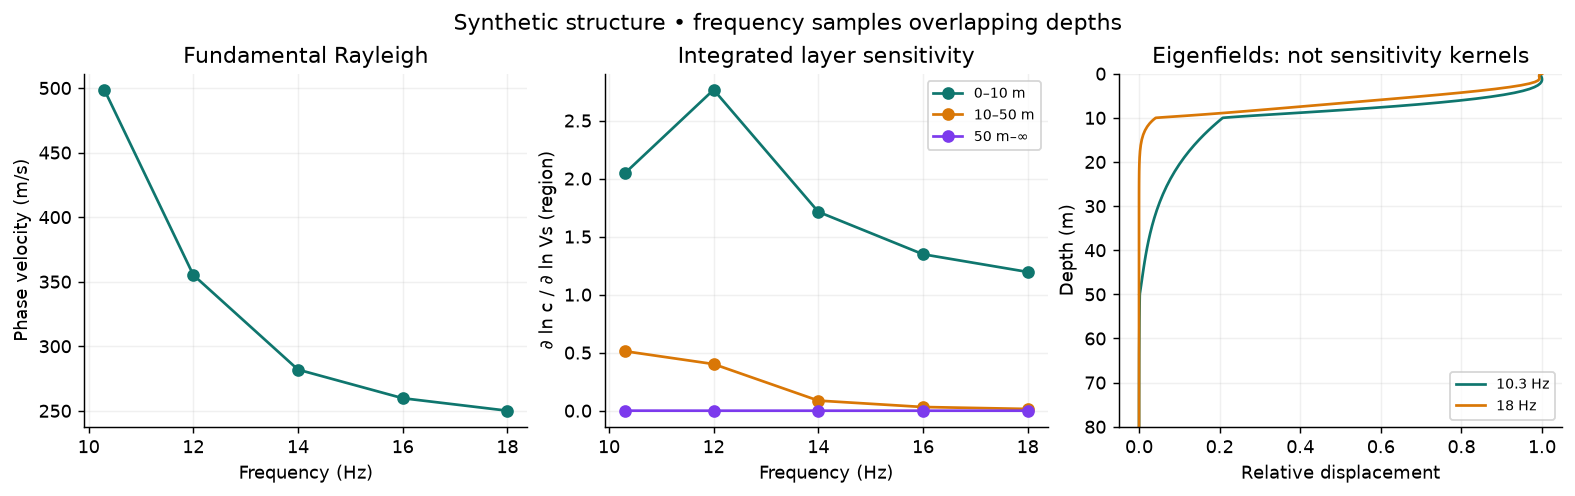

In [2]:
from tutorials.scenarios import critical_zone

model, request = critical_zone()
observation = phase_observation(request, sigma=3e-4)  # 0.03% per-frequency uncertainty
model_table(model)
print("Frequencies (Hz):", request.frequencies_hz)
print("Locked numerical bottom (m):", request.bottom_depth_m)
modes = solve_modes(model, request).fundamental()
operator = linearize_phase(model, request, observation)
G = np.array(operator.g)
sensitivity_figure(modes, operator)

The middle panel contains **integrated layer sensitivities**, not pointwise kernels: $G_{fi}=\partial\ln c(f)/\partial\ln V_{s,i}$. A coefficient changes Vs throughout a physical layer, including its full thickness. The last parameter changes the entire halfspace below 50 m; it does not resolve a narrow anomaly there. Eigenfield amplitudes in the right panel are relative displacement shapes and must not be used as sensitivity kernels.

## 2. Forward-check a small shallow perturbation

Impose −0.05% in the upper 10 m and −0.02% from 10–50 m. These are elastic perturbations chosen for the exercise, not a calibrated conversion from rain to pore pressure or saturation. Re-solve the changed Earth model to check the linear approximation.


Maximum forward/linear discrepancy: 1.639267650221975e-06


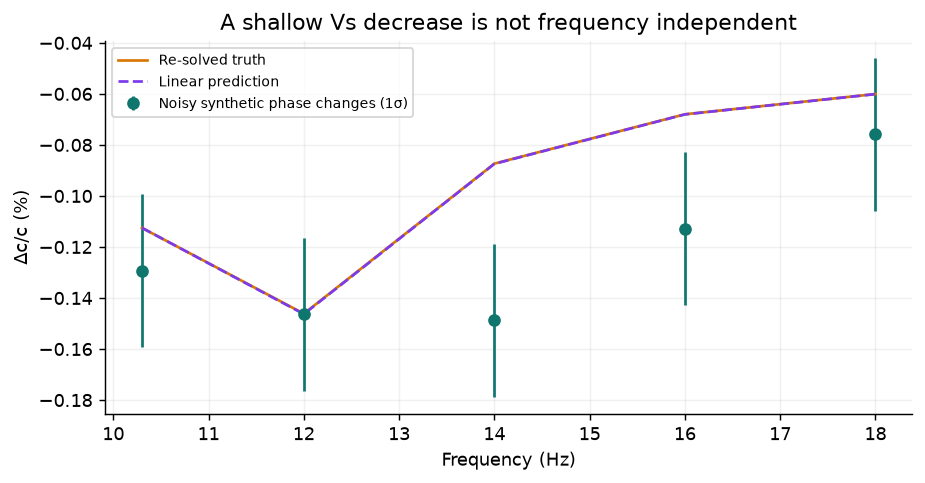

Maximum linearization discrepancy (fraction): 1.639267650221975e-06


In [3]:
truth = np.array([-0.0005, -0.0002, 0.0])
baseline_c = np.array([m.phase_velocity_m_s for m in modes])
changed = solve_modes(perturb_model(model, truth), request).fundamental()
resolved = np.array([m.phase_velocity_m_s for m in changed]) / baseline_c - 1
linear = operator.predict(truth)
linear_error = float(np.max(np.abs(resolved - linear)))
print("Maximum forward/linear discrepancy:", linear_error)
assert linear_error < 0.25 * observation.standard_deviation[0]
Cd = correlated_covariance(len(modes), sigma=3e-4, correlation=0.6)
rng = np.random.default_rng(20261009)
data = resolved + rng.multivariate_normal(np.zeros(len(modes)), Cd)
fig, ax = plt.subplots(figsize=(7, 3.6))
f = np.array(request.frequencies_hz)
ax.errorbar(
    f,
    data * 100,
    yerr=np.sqrt(np.diag(Cd)) * 100,
    fmt="o",
    label="Noisy synthetic phase changes (1σ)",
)
ax.plot(f, resolved * 100, "-", label="Re-solved truth")
ax.plot(f, linear * 100, "--", label="Linear prediction")
ax.set(
    xlabel="Frequency (Hz)",
    ylabel="Δc/c (%)",
    title="A shallow Vs decrease is not frequency independent",
)
ax.legend(fontsize=8)
plt.show()
print("Maximum linearization discrepancy (fraction):", linear_error)

## 3. Infer depth coefficients and inspect resolution

Use a zero-mean Gaussian prior with 0.3% standard deviation in each region. Frequency errors are correlated: neighboring bands are not fully independent measurements. The plotted 95% intervals are conditional on the chosen background, parameterization, covariances, and fixed Vp/density. They exclude uncertainty in the background geology.

The averaging matrix $A$ tells you which combinations of true coefficients appear in the estimated model. Diagonal entries near one and small off-diagonal entries would indicate good regional resolution. A small data residual alone does not establish depth resolution.


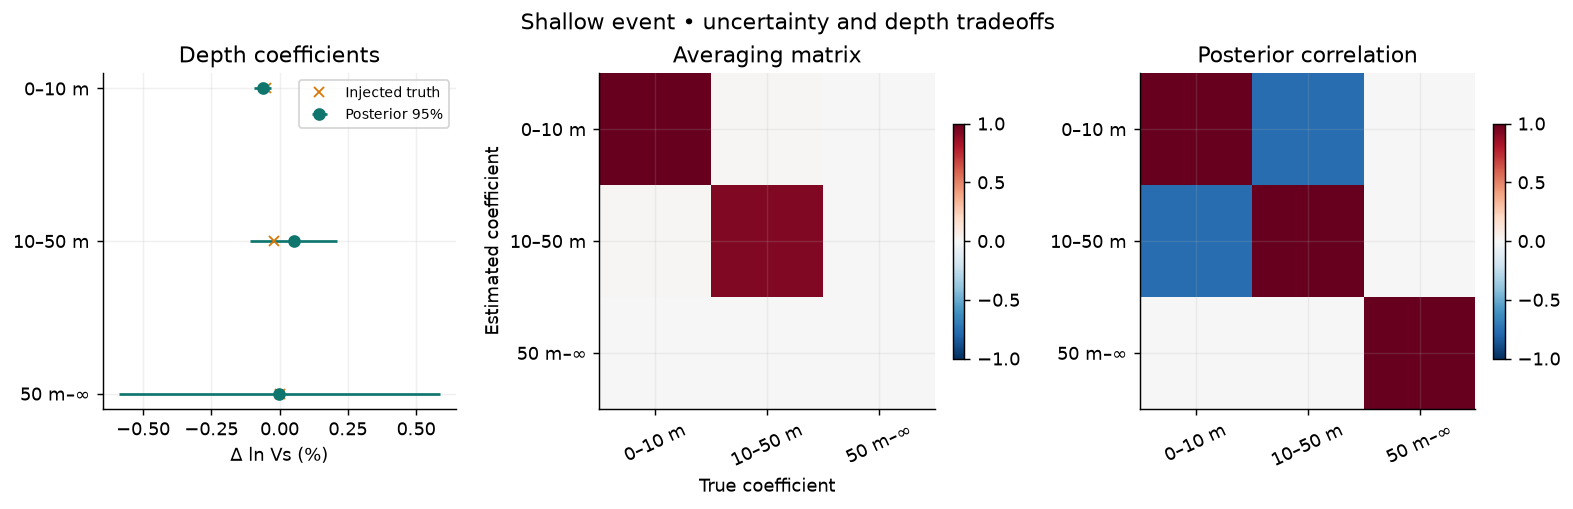

Prior-dominated parameters: (False, False, True)
Prior-scaled, noise-whitened singular values: (29.102110835856188, 3.5118792339949283, 0.0020529887630328487)
Posterior SD, all bands (%): [0.01608 0.08123 0.3    ]
Posterior SD, 10.3–12 Hz only (%): [0.02011 0.10545 0.3    ]


In [4]:
Ca = np.eye(3) * 0.003**2
report = infer_time_lapse(
    operator,
    LinearInverseRequest(
        data_fractional=tuple(data),
        data_covariance=tuple(map(tuple, Cd)),
        prior_mean=(0, 0, 0),
        prior_covariance=tuple(map(tuple, Ca)),
    ),
)
report_figure(operator, truth, report, "Shallow event • uncertainty and depth tradeoffs")
print("Prior-dominated parameters:", report.prior_dominated)
print("Prior-scaled, noise-whitened singular values:", report.whitened_singular_values)
# Does dropping high frequencies change our ability to resolve the shallow layer?
low_indexes = np.array([0, 1])
low_operator = select_band(operator, low_indexes)
low_report = infer_time_lapse(
    low_operator,
    LinearInverseRequest(
        data_fractional=tuple(data[low_indexes]),
        data_covariance=tuple(map(tuple, Cd[np.ix_(low_indexes, low_indexes)])),
        prior_mean=(0, 0, 0),
        prior_covariance=tuple(map(tuple, Ca)),
    ),
)
full_sd = np.sqrt(np.diag(report.covariance_log_vs))
low_sd = np.sqrt(np.diag(low_report.covariance_log_vs))
assert np.all(full_sd <= low_sd + 1e-10)
print("Posterior SD, all bands (%):", full_sd * 100)
print("Posterior SD, 10.3–12 Hz only (%):", low_sd * 100)

## 4. A time series does not identify its cause by itself

Construct 60 synthetic days with a shallow oscillation and a rain-event-shaped transient in the weathered layer. The labels describe how we imposed the changes; the seismic inversion knows only elastic coefficients. Field interpretation requires colocated temperature, rainfall, soil-moisture, groundwater, and loading observations, with lags and competing explanatory models.


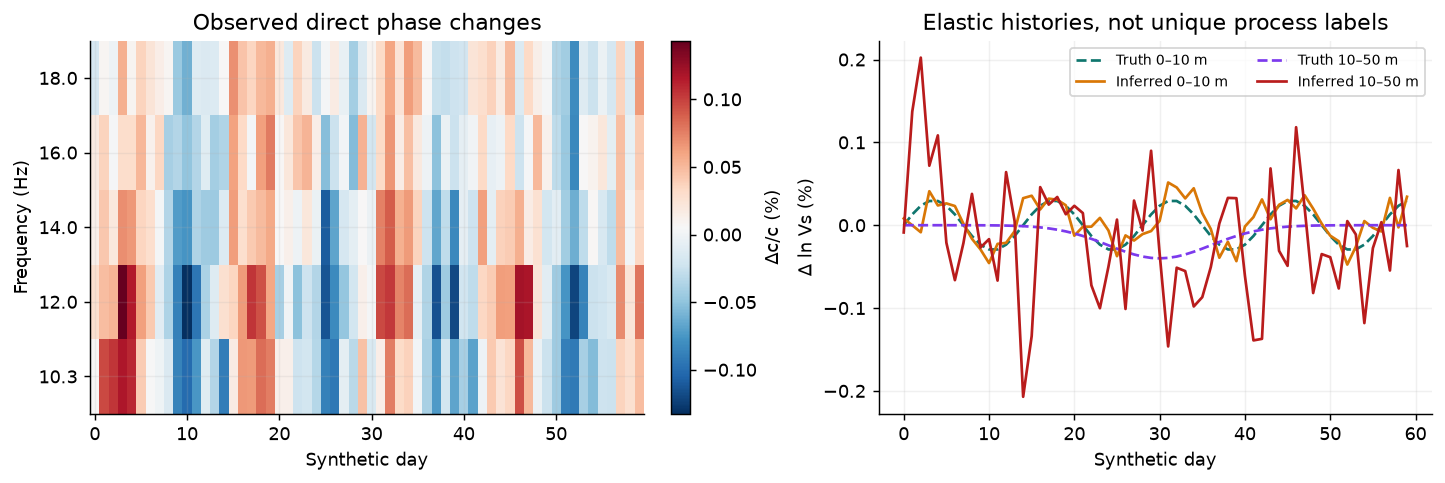

In [5]:
days = np.arange(60)
a_t = np.zeros((len(days), 3))
a_t[:, 0] = 3e-4 * np.sin(2 * np.pi * days / 14)
a_t[:, 1] = -4e-4 * np.exp(-((days - 30) ** 2) / (2 * 6**2))
d_t = a_t @ G.T + rng.multivariate_normal(np.zeros(len(modes)), Cd, size=len(days))
means = []
for d in d_t:
    r = infer_time_lapse(
        operator,
        LinearInverseRequest(
            data_fractional=tuple(d),
            data_covariance=tuple(map(tuple, Cd)),
            prior_mean=(0, 0, 0),
            prior_covariance=tuple(map(tuple, Ca)),
        ),
    )
    means.append(r.mean_log_vs)
means = np.array(means)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
image = axes[0].imshow(
    d_t.T * 100,
    aspect="auto",
    origin="lower",
    cmap="RdBu_r",
    extent=(-0.5, 59.5, -0.5, len(f) - 0.5),
)
axes[0].set(
    yticks=np.arange(len(f)),
    yticklabels=f,
    xlabel="Synthetic day",
    ylabel="Frequency (Hz)",
    title="Observed direct phase changes",
)
fig.colorbar(image, ax=axes[0], label="Δc/c (%)")
for j, label in enumerate(("0–10 m", "10–50 m")):
    axes[1].plot(days, a_t[:, j] * 100, "--", label=f"Truth {label}")
    axes[1].plot(days, means[:, j] * 100, label=f"Inferred {label}")
axes[1].set(
    xlabel="Synthetic day",
    ylabel="Δ ln Vs (%)",
    title="Elastic histories, not unique process labels",
)
axes[1].legend(fontsize=8, ncol=2)
plt.show()

## What would I take to the field?

Select clean direct-wave phase measurements and retain their cross-frequency covariance. Check the background structure, branch identification, and numerical errors before interpreting a small change. Compare full-band and restricted-band posterior resolution. A Vs decrease alone cannot distinguish effective-stress change, crack opening, or thermal effects; a groundwater-depth conversion needs an independently supported hydro-mechanical model.

**Try:** change the shallow thickness, remove 12–18 Hz, increase error correlation, or move the imposed change into the halfspace. Inspect the uncertainty as well as the fitted curve. Changing the background requires recomputing the operator.


In [6]:
assert all(m.qc.status == "passed" for m in modes)
assert max(operator.numerical_phase_error_estimate) < 0.1 * 3e-4
emit_metrics(
    {
        "case": "synthetic critical zone",
        "frequencies_hz": list(f),
        "max_numerical_phase_error": max(operator.numerical_phase_error_estimate),
        "max_linearization_discrepancy": linear_error,
        "posterior_mean_log_vs": list(report.mean_log_vs),
        "posterior_sd_log_vs": full_sd.tolist(),
        "prior_dominated": list(report.prior_dominated),
        "checks_passed": True,
    }
)

{
  "case": "synthetic critical zone",
  "frequencies_hz": [
    10.3,
    12.0,
    14.0,
    16.0,
    18.0
  ],
  "max_numerical_phase_error": 5.3807129862804e-09,
  "max_linearization_discrepancy": 1.639267650221975e-06,
  "posterior_mean_log_vs": [
    -0.000623252137747845,
    0.000521258281279645,
    -1.2672251283485471e-05
  ],
  "posterior_sd_log_vs": [
    0.00016075599122301044,
    0.0008122668369593296,
    0.00299999301908813
  ],
  "prior_dominated": [
    false,
    false,
    true
  ],
  "checks_passed": true
}

case,synthetic critical zone
frequencies hz,"[10.3, 12.0, 14.0, 16.0, 18.0]"
max numerical phase error,5.3807129862804e-09
max linearization discrepancy,1.639267650221975e-06
posterior mean log vs,"[-0.000623252137747845, 0.000521258281279645, -1.2672251283485471e-05]"
posterior sd log vs,"[0.00016075599122301044, 0.0008122668369593296, 0.00299999301908813]"
prior dominated,"[False, False, True]"
checks passed,True
